# AI401 Assignment 1: soil grain-size distribution from photos

CNNs, ViTs and self-supervised encoders on the Kaggle competition
[Predicting Soil Grain Size Distributions from Images](https://www.kaggle.com/competitions/soil-grain-size-from-photos).

The heavy lifting (tiling, training, frozen features, DINO adaptation, interpretation, ensembles) is done by the
scripts in `scripts/` (see `remote/run_all.sh`). Every experiment writes its config, OOF predictions, test
predictions, metrics and compute usage to `results/exps/<name>/`. This notebook reads only `results/`, so it runs
without a GPU or the raw photos. The full report is in [README.md](../README.md).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
ROOT = Path('..').resolve(); R = ROOT / 'results'
sys.path.insert(0, str(ROOT / 'src'))
from soilgs.metric import COLS, SIEVES, LOG_D, DLOG, emd, d_value, d_errors, make_valid, UNIFORM_BASELINE
pd.set_option('display.width', 200, 'display.max_columns', 30)
labels = pd.read_csv(R / 'data/labels.csv'); labels.columns = ['sample_id'] + COLS
Y = labels[COLS].to_numpy(float)

## Part 0. EDA

In [2]:
summary = json.loads((R / 'eda/summary.json').read_text())
photos = pd.read_csv(R / 'eda/photos.csv')
print(json.dumps({k: summary[k] for k in ['n_train_samples', 'n_test_samples', 'n_photos', 'photos_per_sample', 'class_counts']}, indent=1))
display(photos.groupby(['camera']).agg(photos=('photo', 'size'), samples=('sample_id', 'nunique'), ppm=('ppm', 'first'),
        mpix=('mpix', 'median'), fov_w_mm=('field_w_mm', 'median'), fov_h_mm=('field_h_mm', 'median')).round(2))
display(pd.crosstab(photos.split, photos.camera))

{
 "n_train_samples": 24,
 "n_test_samples": 10,
 "n_photos": {
  "train": 127,
  "test": 35
 },
 "photos_per_sample": {
  "count": 34.0,
  "mean": 4.76,
  "std": 1.46,
  "min": 3.0,
  "25%": 3.25,
  "50%": 5.0,
  "75%": 6.0,
  "max": 8.0
 },
 "class_counts": {
  "gravel": 11,
  "fine": 9,
  "sand": 4
 }
}


,photos,samples,ppm,mpix,fov_w_mm,fov_h_mm
camera,,,,,,
iphone14,14,3,13.94,12.19,289.20,216.90
iphone16,21,7,19.52,24.47,292.55,219.41
motorolaedge,69,22,4.60,1.15,348.07,156.63
motorolaedge60fusion,3,1,12.46,9.44,328.60,184.84
samsunga52,55,22,4.55,1.92,351.23,263.59


camera,iphone14,iphone16,motorolaedge,motorolaedge60fusion,samsunga52
split,,,,,
test,14,21,0,0,0
train,0,0,69,3,55


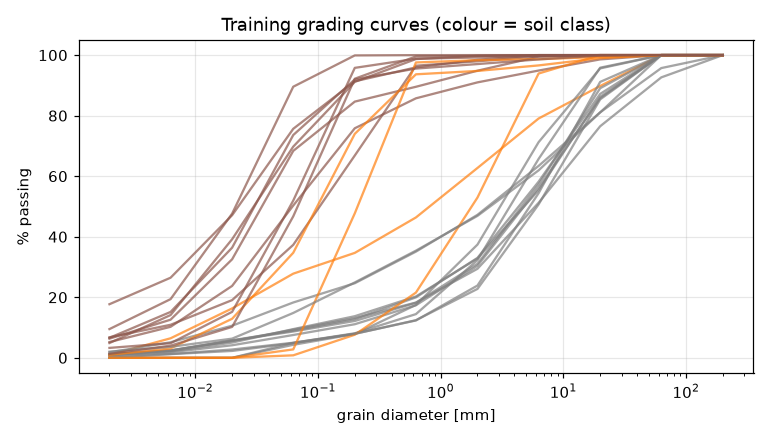

,0,14,17,23,5,15,1,22,20,2,19,3,16,4,21,6,7,11,12,8,9,18,13,10
sample_id,F827,H405,H549,H668,H126,H493,G190,H666,H617,H030,H616,H037,H516,H038,H637,H181,H183,H371,H372,H366,H367,H615,H374,H368
class,fine,fine,fine,fine,fine,fine,fine,fine,sand,fine,sand,sand,sand,gravel,gravel,gravel,gravel,gravel,gravel,gravel,gravel,gravel,gravel,gravel
fines_lt_0063,89.56,75.66,69.76,73.59,68.36,51.95,50.31,46.75,34.7,37.32,2.78,27.8,0.82,18.28,14.82,4.3,4.95,8.94,8.69,9.48,7.54,4.84,9.3,4.98
gravel_gt_2,0.0,1.55,0.25,2.96,5.15,0.79,9.01,0.21,5.23,2.05,1.68,37.28,47.06,52.77,53.11,62.59,67.72,66.99,68.94,67.18,69.59,76.12,70.58,77.24
log10_d50,-1.67,-1.65,-1.52,-1.52,-1.46,-1.23,-1.21,-1.16,-1.01,-0.99,-0.68,-0.09,0.25,0.39,0.4,0.49,0.57,0.64,0.66,0.68,0.68,0.73,0.77,0.79


In [3]:
display(Image(R / 'figures/eda_curves.png'))
curves = pd.read_csv(R / 'eda/curves.csv')
display(curves[['sample_id', 'class', 'fines_lt_0063', 'gravel_gt_2', 'log10_d50']].sort_values('log10_d50').round(2).T)

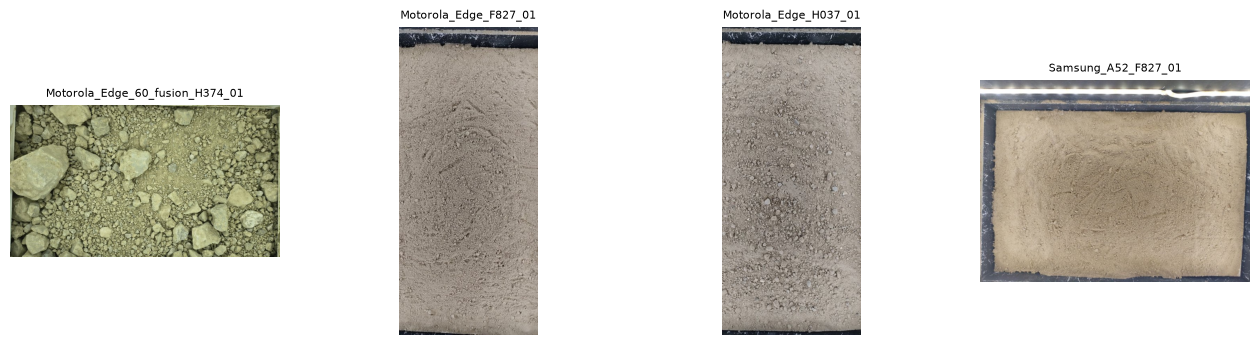

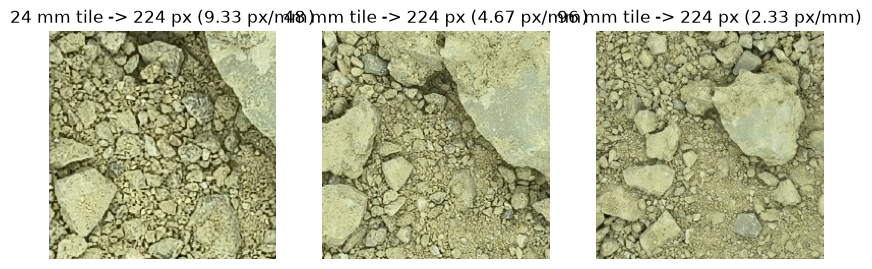

In [4]:
thumbs = sorted((R / 'eda/thumbs').glob('*.jpg'))
full = [t for t in thumbs if '__' not in t.name][:4]
fig, ax = plt.subplots(1, len(full), figsize=(4 * len(full), 4))
for a, t in zip(np.atleast_1d(ax), full):
    a.imshow(plt.imread(t)); a.set_title(t.stem, fontsize=8); a.axis('off')
plt.show()
t0 = full[0].stem
fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, mm in zip(ax, (24, 48, 96)):
    a.imshow(plt.imread(R / f'eda/thumbs/{t0}__{mm}mm.jpg')); a.set_title(f'{mm} mm tile -> 224 px ({224/mm:.2f} px/mm)'); a.axis('off')
plt.show()

## Part 0. Metric

EMD = sum over the 10 intervals of |F_i - F^_i| * (log10 x_{i+1} - log10 x_i), in % x decades, range [0, 500].
It is the area between the two cumulative curves on a log-diameter axis, i.e. the Wasserstein-1 distance
between the two grain-size distributions measured in log10(mm).

In [5]:
def shift_curve(c, decades):
    # the same soil seen at a wrong scale: the curve moves along log d
    return np.interp(LOG_D - decades, LOG_D, c, left=0, right=100)
mid = Y[np.argsort(d_value(Y, 50))[len(Y) // 2]]
rows = []
for k in (1.41, 2, 4):
    s = shift_curve(mid, np.log10(k))
    rows.append({'scale error': f'x{k}', 'EMD (median soil)': emd(mid, s), 'theory 100*log10(k)': 100 * np.log10(k)})
display(pd.DataFrame(rows).round(2))
print('uniform Kaggle baseline vs training curves, mean EMD:', emd(Y, UNIFORM_BASELINE[None]).mean().round(2))
print('training mean (in-sample, optimistic):', emd(Y, Y.mean(0, keepdims=True)).mean().round(2))
print('training median curve (L1-optimal per sieve):', emd(Y, np.median(Y, 0, keepdims=True)).mean().round(2))

,scale error,EMD (median soil),theory 100*log10(k)
0,x1.41,14.93,14.92
1,x2,30.13,30.10
2,x4,60.21,60.21


uniform Kaggle baseline vs training curves, mean EMD: 102.02
training mean (in-sample, optimistic): 86.14
training median curve (L1-optimal per sieve): 83.25


**Strengths:** a physically meaningful distance (area between the grading curves), every decade weighs the
same, it is linear in the error so outliers do not dominate, and it is the natural loss for a cumulative target.

**Weaknesses and edge cases:**
- The grid is coarse (11 points, about 0.5 decade apart). A shift inside one interval is invisible until it crosses a sieve.
- The clay/silt end (0.002-0.063 mm) carries 1.5 of the 5 decades, but it is invisible in a photo, so a large
  part of the score is decided by what the camera cannot resolve.
- A wrong pixels-per-mm by x2 costs 30 EMD by itself (see the table), more than the gap between a trivial and a good model.
- The last point is fixed at 100, and the 63-200 mm interval contributes almost nothing for fine soils.

**Complementary metric:** errors of D10 / D30 / D50 / D60 in decades (|log10 D^ - log10 D|). Engineers use
these numbers (Cu = D60/D10, Cc = D30²/(D10·D60)), and the error reads as a factor (0.30 = factor 2).
All runs report them (`D50_err_dec`).

**Alternative target:** the 11 bin masses (mass fraction between consecutive sieves), predicted with a softmax
and accumulated. The prediction is then valid by construction (non-negative increments, ends at 100), and the
EMD can be the training loss itself. All neural models here use this head.

In [6]:
# complementary metric on a toy example, and why isotonic repair beats a running maximum
yhat = np.array([10, 35, 30, 80, 105.])
print('running max  ', make_valid(yhat, 'max')[0], '\nisotonic PAV ', make_valid(yhat, 'isotonic')[0])
print(d_errors(Y[:3], shift_curve(Y[0], np.log10(2))[None].repeat(3, 0)))

running max   [ 10.  35.  35.  80. 100.] 
isotonic PAV  [ 10.   32.5  32.5  80.  100. ]
{'D10': 0.15518391544421117, 'D30': 0.24956393227480142, 'D50': 0.29702885979306376, 'D60': 0.32999682669912095}


## Part 0. Validation and tiles

- **Folds:** 6 group folds over physical samples (all photos of a sample are on the same side), stratified by
  D50 (each block of 6 samples sorted by D50 is dealt to the 6 folds). Every experiment uses the same
  `results/data/folds.csv`. Predictions are averaged tile -> photo -> sample before scoring.
- **Scale:** ppm comes from `ppm_updated.csv` scaled to the stored photo size (the Motorola Edge photos are stored at
  1600 px instead of 4000, so 11.49 -> 4.60 px/mm; Samsung A52 26.33 -> 4.55 px/mm). As a check of that table,
  the Samsung scale was also estimated without labels by matching texture spectra with the Motorola photos of the
  same soils (`scripts/calibrate.py`, figure below): 4.8 px/mm, +5%, the same bias the method shows on a
  Motorola-vs-Motorola self-check.
- **Tiles:** every photo is resampled to 4.67 px/mm, the native density of the training photos, so test iPhone
  photos are only downsampled and train photos are never upsampled. 48 mm x 48 mm tiles (224 px, 50% overlap,
  central 70% of the frame, at most 48 per photo) are cached once. 48 mm holds several medium-gravel grains, and
  0.21 mm/px still resolves coarse sand. 24 mm and 96 mm caches are kept as an ablation (Part 1).

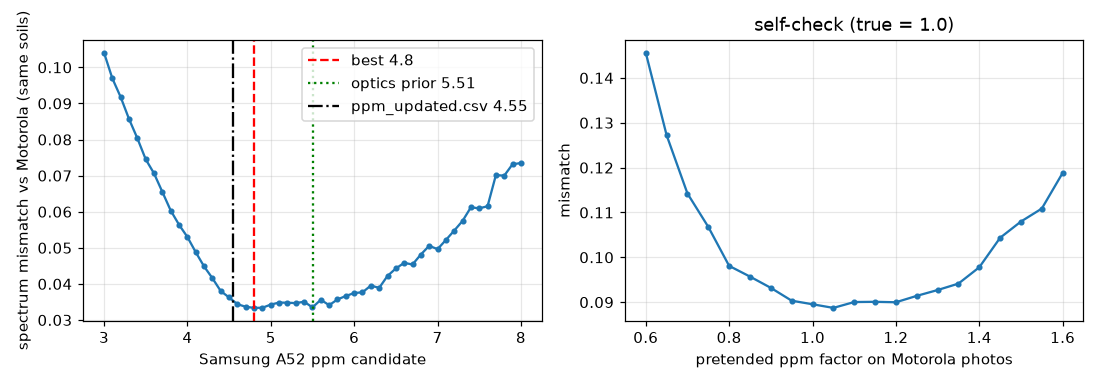

,samples,classes,d50_mm
fold,,,
0,4,"fine, gravel, gravel, sand","0.035, 0.21, 2.5, 6.1"
1,4,"fine, gravel, gravel, sand","0.059, 0.099, 4.3, 5.3"
2,4,"fine, fine, gravel, gravel","0.022, 0.1, 2.4, 4.8"
3,4,"fine, gravel, sand, sand","0.021, 0.81, 1.8, 5.9"
4,4,"fine, fine, gravel, gravel","0.03, 0.062, 3.7, 4.8"
5,4,"fine, fine, gravel, gravel","0.03, 0.068, 3.1, 4.6"


In [7]:
display(Image(R / 'calibration/samsung_ppm.png'))
folds = pd.read_csv(R / 'data/folds.csv')
display(folds.merge(curves[['sample_id', 'class']]).groupby('fold').agg(samples=('sample_id', 'size'),
        classes=('class', lambda s: ', '.join(sorted(s))), d50_mm=('log10_d50', lambda s: ', '.join(f'{10**v:.2g}' for v in sorted(s)))))

## Results table (all experiments)

In [8]:
display(Markdown((R / 'tables.md').read_text()))

# Results

CV = mean ± std over the 6 group folds of the per-sample log-EMD (lower is better). LB = Kaggle public leaderboard (private is hidden until the competition ends).


## Baselines and shortcut controls

| name             | CV (mean ± std)   |   D50_err_dec |   lb_public |   gpu_hours |   peak_mem_gb | setup   |
|:-----------------|:------------------|--------------:|------------:|------------:|--------------:|:--------|
| ctrl_colour_only | 49.689 ± 15.760   |         0.424 |     nan     |       0.000 |         0.000 |         |
| base_train_mean  | 86.632 ± 3.037    |         0.923 |     102.372 |       0.000 |         0.000 |         |
| ctrl_camera_only | 87.055 ± 2.713    |         0.929 |     nan     |       0.000 |         0.000 |         |
| base_uniform     | 102.020 ± 5.477   |         0.914 |     nan     |       0.000 |         0.000 |         |


## Part 1 — CNNs

| name                             | CV (mean ± std)   |   D50_err_dec |   lb_public |   gpu_hours |   peak_mem_gb | setup                                                                                                    |
|:---------------------------------|:------------------|--------------:|------------:|------------:|--------------:|:---------------------------------------------------------------------------------------------------------|
| cnn_r18_bs8_grouped_frozenbn     | 35.878 ± 17.187   |         0.313 |      86.289 |       0.053 |         3.210 | opt=adamw, lr=0.0003, norm=frozen_bn, aug=basic, sampler=grouped, batch=8, mode=ft, tile_mm=48           |
| cnn_r18_bs8_grouped_frozenbn_tth | 35.878 ± 17.187   |         0.313 |     nan     |       0.053 |         3.210 | opt=adamw, lr=0.0003, norm=frozen_bn, aug=basic, sampler=grouped, batch=8, mode=ft, tile_mm=48           |
| mix_cnn_r18_bs8_grouped_frozenbn | 36.395 ± 18.125   |         0.321 |     nan     |       0.058 |         3.210 | opt=adamw, lr=0.0003, norm=frozen_bn, aug=basic, sampler=grouped, batch=8, mode=ft, tile_mm=48           |
| cnn_r18_groupnorm                | 37.527 ± 16.186   |         0.330 |     nan     |       0.018 |         5.030 | opt=adamw, lr=0.0003, norm=groupnorm, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48        |
| cnn_r18_frozenbn                 | 39.497 ± 18.297   |         0.337 |     nan     |       0.015 |         3.210 | opt=adamw, lr=0.0003, norm=frozen_bn, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48        |
| cnn_convnext_t_sgd               | 39.525 ± 18.650   |         0.351 |     nan     |       0.036 |         4.520 | opt=sgd, lr=0.01, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48              |
| cnn_r18_sgd                      | 40.340 ± 21.109   |         0.363 |     nan     |       0.016 |         3.210 | opt=sgd, lr=0.01, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48              |
| cnn_r50_adamw                    | 41.354 ± 18.897   |         0.364 |     nan     |       0.035 |         3.750 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| cnn_r18_noaug                    | 41.422 ± 16.618   |         0.373 |     nan     |       0.015 |         3.210 | opt=adamw, lr=0.0003, norm=default, aug=none, sampler=by_sample, batch=32, mode=ft, tile_mm=48           |
| cnn_r18_tile24mm                 | 41.894 ± 19.339   |         0.382 |     nan     |       0.015 |         2.360 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=24          |
| cnn_r18_const_nowarm             | 42.205 ± 17.394   |         0.372 |     nan     |       0.016 |         3.210 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| cnn_r18_img112                   | 42.464 ± 19.404   |         0.371 |     nan     |       0.015 |         2.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, img=112, tile_mm=48 |
| cnn_effb0_adamw                  | 42.798 ± 18.207   |         0.384 |     nan     |       0.096 |         3.710 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| cnn_r18_tile96mm                 | 43.072 ± 17.428   |         0.387 |     nan     |       0.015 |         1.200 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=96          |
| cnn_r18_adamw                    | 43.280 ± 20.463   |         0.390 |     nan     |       0.018 |         3.210 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| cnn_convnext_t_adamw             | 44.576 ± 20.304   |         0.398 |     nan     |       0.071 |         4.520 | opt=adamw, lr=0.0001, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| cnn_r18_strongaug                | 46.087 ± 22.261   |         0.432 |     nan     |       0.015 |         3.210 | opt=adamw, lr=0.0003, norm=default, aug=strong, sampler=by_sample, batch=32, mode=ft, tile_mm=48         |
| cnn_r18_bs8_grouped              | 50.851 ± 22.334   |         0.481 |     nan     |       0.056 |         3.210 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=grouped, batch=8, mode=ft, tile_mm=48             |


## Part 2 — ViTs

| name                 | CV (mean ± std)   |   D50_err_dec |   lb_public |   gpu_hours |   peak_mem_gb | setup                                                                                                                      |
|:---------------------|:------------------|--------------:|------------:|------------:|--------------:|:---------------------------------------------------------------------------------------------------------------------------|
| mix_vit_scratch      | 34.529 ± 17.261   |         0.299 |     nan     |       0.048 |         2.530 | opt=adamw, lr=0.0005, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                            |
| vit_scratch          | 35.280 ± 17.046   |         0.302 |      79.345 |       0.038 |         2.530 | opt=adamw, lr=0.0005, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                            |
| vit_scratch_tth      | 35.280 ± 17.046   |         0.302 |     nan     |       0.038 |         2.530 | opt=adamw, lr=0.0005, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                            |
| vit_deit_s_sgd       | 40.226 ± 20.866   |         0.351 |     nan     |       0.030 |         3.330 | opt=sgd, lr=0.01, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48              |
| vit_maxvit_t         | 42.268 ± 19.321   |         0.381 |     nan     |       0.141 |         7.600 | opt=adamw, lr=0.0001, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                            |
| vit_deit_s_img112    | 42.396 ± 19.926   |         0.384 |     nan     |       0.033 |         2.640 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, img=112, tile_mm=48 |
| vit_swin_t           | 42.764 ± 21.414   |         0.393 |     nan     |       0.052 |         5.470 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| vit_deit_s_strongaug | 44.426 ± 20.994   |         0.398 |     nan     |       0.036 |         3.410 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=strong, sampler=by_sample, batch=32, mode=ft, tile_mm=48         |
| vit_deit_s_wd_all    | 45.522 ± 20.240   |         0.418 |     nan     |       0.031 |         3.410 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| vit_deit_s           | 45.627 ± 20.508   |         0.419 |     nan     |       0.032 |         3.400 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| vit_deit_s_nollrd    | 45.848 ± 18.826   |         0.427 |     nan     |       0.030 |         3.410 | opt=adamw, lr=0.0001, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                            |
| vit_deit_s_nowarm    | 46.344 ± 20.437   |         0.426 |     nan     |       0.033 |         3.410 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |
| vit_deit_s_dp0       | 47.675 ± 18.989   |         0.440 |     nan     |       0.032 |         3.410 | opt=adamw, lr=0.0001, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48          |


## Part 3 — self-supervised encoders

| name                         | CV (mean ± std)   |   D50_err_dec |   lb_public |   gpu_hours |   peak_mem_gb | setup                                                                                                                           |     cka |
|:-----------------------------|:------------------|--------------:|------------:|------------:|--------------:|:--------------------------------------------------------------------------------------------------------------------------------|--------:|
| ssl_dinov3_s_ft              | 34.059 ± 16.043   |         0.286 |      79.853 |       0.048 |         3.710 | opt=adamw, lr=5e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                |   0.802 |
| ssl_dinov3_s_ft_tth          | 34.059 ± 16.043   |         0.286 |     nan     |       0.048 |         3.710 | opt=adamw, lr=5e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                |   0.802 |
| mix_ssl_dinov3_s_ft          | 34.637 ± 16.336   |         0.296 |     nan     |       0.050 |         3.720 | opt=adamw, lr=5e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                |   0.809 |
| dinov2_s_da_ridge_block4     | 36.508 ± 12.872   |         0.290 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block4, tile_mm=48    | nan     |
| dinov2_s_da_ridge_block4_tth | 36.508 ± 12.872   |         0.290 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block4, tile_mm=48    | nan     |
| dinov3_s_knn_clspatch        | 36.564 ± 10.473   |         0.305 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=knn, features=cls+patch, tile_mm=48   | nan     |
| dinov3_s_knn_clspatch_tth    | 36.564 ± 10.473   |         0.305 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=knn, features=cls+patch, tile_mm=48   | nan     |
| dinov2_s_da_knn_clspatch     | 37.331 ± 13.412   |         0.321 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=knn, features=cls+patch, tile_mm=48   | nan     |
| ssl_dinov3_s_lpft            | 37.693 ± 17.814   |         0.326 |     nan     |       0.056 |         3.710 | opt=adamw, lr=2e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=lpft, tile_mm=48              |   0.966 |
| deit_s_knn_clspatch          | 37.966 ± 13.966   |         0.320 |     nan     |       0.000 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=knn, features=cls+patch, tile_mm=48   | nan     |
| dinov2_s_knn_clspatch        | 39.227 ± 13.032   |         0.327 |     nan     |       0.001 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=knn, features=cls+patch, tile_mm=48   | nan     |
| deit_s_ridge_block4          | 40.588 ± 16.638   |         0.345 |     nan     |       0.000 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block4, tile_mm=48    | nan     |
| dinov2_s_ridge_block4        | 40.606 ± 17.393   |         0.325 |     nan     |       0.001 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block4, tile_mm=48    | nan     |
| ssl_dinov2_s_lpft            | 40.700 ± 20.682   |         0.375 |     nan     |       0.043 |         3.840 | opt=adamw, lr=2e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=lpft, tile_mm=48              |   0.839 |
| deit_s_ridge_block8          | 40.860 ± 17.068   |         0.344 |     nan     |       0.000 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block8, tile_mm=48    | nan     |
| deit_s_lp_clspatch           | 41.384 ± 19.258   |         0.354 |     nan     |       0.001 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=lp, features=cls+patch, tile_mm=48    | nan     |
| dinov3_s_ridge_cls           | 41.433 ± 15.368   |         0.330 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls, tile_mm=48       | nan     |
| deit_s_ridge_patch           | 41.707 ± 16.169   |         0.334 |     nan     |       0.000 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=patch, tile_mm=48     | nan     |
| dinov3_s_ridge_clspatch      | 41.760 ± 16.889   |         0.328 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls+patch, tile_mm=48 | nan     |
| deit_s_ridge_clspatch        | 41.885 ± 17.533   |         0.361 |     nan     |       0.000 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls+patch, tile_mm=48 | nan     |
| dinov3_s_ridge_patch         | 42.046 ± 17.249   |         0.329 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=patch, tile_mm=48     | nan     |
| dinov2_s_ridge_patch         | 42.430 ± 15.250   |         0.337 |     nan     |       0.001 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=patch, tile_mm=48     | nan     |
| dinov2_s_ridge_clspatch      | 42.466 ± 15.823   |         0.338 |     nan     |       0.001 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls+patch, tile_mm=48 | nan     |
| dinov2_s_ridge_cls           | 42.631 ± 15.415   |         0.339 |     nan     |       0.001 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls, tile_mm=48       | nan     |
| dinov3_s_ridge_block4        | 42.876 ± 15.690   |         0.362 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block4, tile_mm=48    | nan     |
| dinov2_s_ridge_block8        | 43.041 ± 16.322   |         0.337 |     nan     |       0.001 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block8, tile_mm=48    | nan     |
| dinov3_s_ridge_block8        | 43.481 ± 17.434   |         0.343 |     nan     |       0.001 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block8, tile_mm=48    | nan     |
| ssl_dinov2_s_ft              | 44.089 ± 21.964   |         0.397 |     nan     |       0.037 |         3.850 | opt=adamw, lr=5e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, tile_mm=48                |   0.683 |
| dinov2_s_lp_clspatch         | 44.283 ± 16.658   |         0.395 |     nan     |       0.002 |         3.440 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=lp, features=cls+patch, tile_mm=48    | nan     |
| dinov2_s_da_ridge_block8     | 44.313 ± 15.742   |         0.351 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=block8, tile_mm=48    | nan     |
| ssl_dinov3_s_lora            | 44.895 ± 21.064   |         0.429 |     nan     |       0.048 |         3.070 | opt=adamw, lr=0.001, norm=default, aug=basic, sampler=by_sample, batch=32, mode=lora, tile_mm=48                                |   0.694 |
| dinov3_s_lp_clspatch         | 45.036 ± 17.564   |         0.395 |     nan     |       0.002 |         3.250 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=lp, features=cls+patch, tile_mm=48    | nan     |
| deit_s_ridge_cls             | 45.201 ± 20.007   |         0.391 |     nan     |       0.000 |         3.160 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls, tile_mm=48       | nan     |
| dinov2_s_da_lp_clspatch      | 45.792 ± 17.431   |         0.404 |     nan     |       0.002 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=lp, features=cls+patch, tile_mm=48    | nan     |
| ssl_dinov2_s_lora            | 46.539 ± 21.161   |         0.441 |     nan     |       0.036 |         3.130 | opt=adamw, lr=0.001, norm=default, aug=basic, sampler=by_sample, batch=32, mode=lora, tile_mm=48                                |   0.647 |
| dinov2_s_da_ridge_patch      | 46.943 ± 15.203   |         0.383 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=patch, tile_mm=48     | nan     |
| ssl_dinov2_s_da_lpft         | 47.469 ± 19.303   |         0.443 |     nan     |       0.044 |         3.850 | opt=adamw, lr=2e-05, layer_decay=0.75, norm=default, aug=basic, sampler=by_sample, batch=32, mode=lpft, tile_mm=48              |   0.868 |
| dinov2_s_da_ridge_clspatch   | 48.168 ± 14.346   |         0.404 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls+patch, tile_mm=48 | nan     |
| ssl_dinov2_s_da_lora         | 48.942 ± 17.979   |         0.463 |     nan     |       0.035 |         3.130 | opt=adamw, lr=0.001, norm=default, aug=basic, sampler=by_sample, batch=32, mode=lora, tile_mm=48                                |   0.622 |
| dinov2_s_da_ridge_cls        | 49.502 ± 14.554   |         0.430 |     nan     |       0.001 |         3.460 | opt=adamw, lr=0.0003, norm=default, aug=basic, sampler=by_sample, batch=32, mode=ft, head=ridge, features=cls, tile_mm=48       | nan     |


## Part 7 — ensembles

| name                | CV (mean ± std)   |   D50_err_dec |   lb_public |   gpu_hours |   peak_mem_gb | setup   |
|:--------------------|:------------------|--------------:|------------:|------------:|--------------:|:--------|
| ens_top5            | 33.525 ± 15.809   |         0.286 |      77.083 |       0.000 |         0.000 |         |
| ens_top5_tth        | 33.525 ± 15.809   |         0.286 |     nan     |       0.000 |         0.000 |         |
| ens_diverse3        | 33.675 ± 14.055   |         0.283 |     nan     |       0.000 |         0.000 |         |
| ens_best_per_family | 33.920 ± 16.921   |         0.296 |     nan     |       0.000 |         0.000 |         |
| ens_top3            | 33.920 ± 16.921   |         0.296 |     nan     |       0.000 |         0.000 |         |
| ens_diverse2        | 33.927 ± 15.188   |         0.293 |     nan     |       0.000 |         0.000 |         |


## Controls and scale robustness (CV EMD)

| name                             |   cv_mean |   ctrl_shuffle |   ctrl_grey |   scale_ref |   res_0.5 |   res_0.25 |   ppm_x0.5 |   ppm_x2 |
|:---------------------------------|----------:|---------------:|------------:|------------:|----------:|-----------:|-----------:|---------:|
| cnn_r18_bs8_grouped_frozenbn     |     35.88 |          35.66 |       35.13 |       36.39 |     36.90 |      39.74 |      46.35 |    42.39 |
| cnn_r18_bs8_grouped_frozenbn_tth |     35.88 |          35.66 |       35.13 |       36.39 |     36.90 |      39.74 |      46.35 |    42.39 |
| mix_cnn_r18_bs8_grouped_frozenbn |     36.39 |          36.64 |       37.02 |       36.53 |     35.46 |      38.91 |      46.04 |    44.12 |
| cnn_r18_groupnorm                |     37.53 |          37.42 |       42.41 |       37.84 |     38.37 |      41.18 |      41.83 |    39.65 |
| cnn_r18_frozenbn                 |     39.50 |          39.23 |       45.61 |       39.50 |     36.59 |      38.97 |      41.64 |    41.19 |
| cnn_convnext_t_sgd               |     39.52 |          39.79 |       43.55 |       39.84 |     39.87 |      41.03 |      39.11 |    39.58 |
| cnn_r18_sgd                      |     40.34 |          40.17 |       39.06 |       40.20 |     38.60 |      51.62 |      47.28 |    39.54 |
| cnn_r50_adamw                    |     41.35 |          40.08 |       39.15 |       41.59 |     37.50 |      51.86 |      43.56 |    40.10 |
| cnn_r18_noaug                    |     41.42 |          42.22 |       47.22 |       41.33 |     43.47 |      45.05 |      45.22 |    38.54 |
| cnn_r18_const_nowarm             |     42.20 |          42.15 |       45.92 |       42.14 |     46.08 |      52.17 |      42.62 |    38.37 |
| cnn_r18_img112                   |     42.46 |          42.64 |       42.94 |       42.16 |     43.78 |      40.88 |      43.19 |    34.47 |
| cnn_effb0_adamw                  |     42.80 |          44.06 |       38.53 |       42.83 |     42.55 |      58.79 |      47.76 |    39.46 |
| cnn_r18_adamw                    |     43.28 |          43.42 |       44.06 |       43.37 |     43.24 |      42.72 |      43.63 |    36.04 |
| cnn_convnext_t_adamw             |     44.58 |          45.03 |       43.46 |       44.48 |     42.15 |      36.03 |      40.83 |    43.91 |
| cnn_r18_strongaug                |     46.09 |          46.95 |       47.46 |       45.82 |     42.61 |      40.20 |      41.38 |    40.33 |
| cnn_r18_bs8_grouped              |     50.85 |          51.65 |       55.80 |       51.11 |     53.36 |      59.14 |      53.65 |    57.98 |
| ssl_dinov3_s_ft                  |     34.06 |          33.77 |       34.15 |       34.19 |     34.38 |      35.87 |      39.81 |    37.93 |
| ssl_dinov3_s_ft_tth              |     34.06 |          33.77 |       34.15 |       34.19 |     34.38 |      35.87 |      39.81 |    37.93 |
| mix_ssl_dinov3_s_ft              |     34.64 |          34.55 |       34.69 |       34.66 |     34.80 |      35.42 |      39.80 |    39.43 |
| dinov2_s_da_ridge_block4         |     36.51 |          37.06 |       54.66 |       37.60 |     48.83 |      61.99 |      53.71 |    53.75 |
| dinov2_s_da_ridge_block4_tth     |     36.51 |          37.06 |       54.66 |       37.60 |     48.83 |      61.99 |      53.71 |    53.75 |
| dinov3_s_knn_clspatch            |     36.56 |          38.80 |       38.38 |       36.88 |     38.31 |      38.31 |      39.03 |    37.85 |
| dinov3_s_knn_clspatch_tth        |     36.56 |          38.80 |       38.38 |       36.88 |     38.31 |      38.31 |      39.03 |    37.85 |
| dinov2_s_da_knn_clspatch         |     37.33 |          39.30 |       34.76 |       38.29 |     39.98 |      48.82 |      36.70 |    45.30 |
| ssl_dinov3_s_lpft                |     37.69 |          37.87 |       37.74 |       37.72 |     37.51 |      37.31 |      39.98 |    40.57 |
| deit_s_knn_clspatch              |     37.97 |          39.74 |       40.23 |       38.59 |     40.09 |      39.87 |      37.93 |    37.78 |
| dinov2_s_knn_clspatch            |     39.23 |          38.41 |       38.60 |       40.75 |     39.87 |      39.16 |      41.59 |    36.80 |
| deit_s_ridge_block4              |     40.59 |          41.10 |       51.91 |       41.28 |     48.29 |      60.89 |      52.53 |    53.64 |
| dinov2_s_ridge_block4            |     40.61 |          41.40 |       45.86 |       41.72 |     53.58 |      67.52 |      49.65 |    60.40 |
| ssl_dinov2_s_lpft                |     40.70 |          41.01 |       43.19 |       40.97 |     41.06 |      40.21 |      40.80 |    41.77 |
| deit_s_ridge_block8              |     40.86 |          43.25 |       45.03 |       41.85 |     46.66 |      54.38 |      47.55 |    51.66 |
| deit_s_lp_clspatch               |     41.38 |          42.35 |       56.74 |       41.57 |     41.95 |      40.40 |      45.25 |    45.19 |
| dinov3_s_ridge_cls               |     41.43 |          41.59 |       44.44 |       42.41 |     42.84 |      45.17 |      41.51 |    45.46 |
| deit_s_ridge_patch               |     41.71 |          44.96 |       42.64 |       42.56 |     49.20 |      54.58 |      46.08 |    47.28 |
| dinov3_s_ridge_clspatch          |     41.76 |          42.01 |       42.58 |       42.42 |     42.56 |      44.68 |      42.80 |    47.37 |
| deit_s_ridge_clspatch            |     41.88 |          43.58 |       45.32 |       42.45 |     48.51 |      55.04 |      45.49 |    49.37 |
| dinov3_s_ridge_patch             |     42.05 |          42.57 |       41.38 |       42.52 |     42.80 |      45.70 |      43.91 |    50.22 |
| dinov2_s_ridge_patch             |     42.43 |          44.90 |       41.60 |       42.77 |     43.32 |      48.81 |      41.92 |    48.02 |
| dinov2_s_ridge_clspatch          |     42.47 |          44.77 |       41.42 |       43.10 |     43.68 |      48.11 |      41.31 |    47.59 |
| dinov2_s_ridge_cls               |     42.63 |          45.08 |       41.48 |       43.62 |     44.41 |      47.80 |      41.05 |    47.34 |
| dinov3_s_ridge_block4            |     42.88 |          43.88 |       50.44 |       44.21 |     56.35 |      61.13 |      53.29 |    65.33 |
| dinov2_s_ridge_block8            |     43.04 |          45.59 |       43.73 |       43.23 |     45.05 |      54.18 |      46.63 |    51.25 |
| dinov3_s_ridge_block8            |     43.48 |          46.38 |       44.26 |       43.57 |     46.82 |      60.84 |      47.83 |    51.21 |
| ssl_dinov2_s_ft                  |     44.09 |          44.28 |       42.98 |       44.47 |     41.11 |      39.30 |      41.12 |    42.37 |
| dinov2_s_lp_clspatch             |     44.28 |          48.36 |       50.23 |       44.51 |     43.82 |      41.76 |      42.51 |    49.35 |
| dinov2_s_da_ridge_block8         |     44.31 |          45.15 |       45.65 |       44.82 |     46.48 |      58.54 |      46.02 |    55.85 |
| ssl_dinov3_s_lora                |     44.89 |          45.73 |       47.25 |       44.51 |     47.97 |      50.07 |      51.56 |    40.89 |
| dinov3_s_lp_clspatch             |     45.04 |          46.02 |       49.34 |       44.87 |     45.49 |      50.43 |      48.63 |    45.35 |
| deit_s_ridge_cls                 |     45.20 |          45.54 |       50.59 |       45.07 |     49.40 |      59.33 |      47.29 |    54.76 |
| dinov2_s_da_lp_clspatch          |     45.79 |          46.96 |       47.04 |       45.35 |     48.08 |      47.69 |      48.76 |    40.70 |
| ssl_dinov2_s_lora                |     46.54 |          46.88 |       45.13 |       46.13 |     44.42 |      40.82 |      41.71 |    38.18 |
| dinov2_s_da_ridge_patch          |     46.94 |          48.33 |       46.86 |       47.85 |     49.98 |      58.35 |      46.69 |    54.68 |
| ssl_dinov2_s_da_lpft             |     47.47 |          47.76 |       46.47 |       47.43 |     44.34 |      43.81 |      41.39 |    45.56 |
| dinov2_s_da_ridge_clspatch       |     48.17 |          49.16 |       48.28 |       49.20 |     51.26 |      59.26 |      47.90 |    56.49 |
| ssl_dinov2_s_da_lora             |     48.94 |          48.91 |       40.93 |       48.81 |     45.05 |      47.85 |      43.83 |    41.56 |
| dinov2_s_da_ridge_cls            |     49.50 |          49.69 |       49.86 |       50.45 |     52.88 |      60.50 |      49.26 |    59.23 |
| mix_vit_scratch                  |     34.53 |          34.43 |       46.62 |       34.45 |     35.91 |      42.41 |      45.84 |    40.32 |
| vit_scratch                      |     35.28 |          35.57 |       48.83 |       34.91 |     36.92 |      45.06 |      45.32 |    39.04 |
| vit_scratch_tth                  |     35.28 |          35.57 |       48.83 |       34.91 |     36.92 |      45.06 |      45.32 |    39.04 |
| vit_deit_s_sgd                   |     40.23 |          40.76 |       42.33 |       40.12 |     38.87 |      39.88 |      39.73 |    39.11 |
| vit_maxvit_t                     |     42.27 |          41.98 |       36.74 |       42.00 |     40.46 |      43.45 |      36.11 |    39.95 |
| vit_deit_s_img112                |     42.40 |          42.73 |       49.62 |       42.39 |     41.13 |      39.03 |      39.08 |    43.77 |
| vit_swin_t                       |     42.76 |          43.15 |       43.91 |       42.78 |     39.76 |      39.90 |      40.72 |    40.80 |
| vit_deit_s_strongaug             |     44.43 |          44.96 |       48.45 |       44.08 |     43.42 |      37.02 |      40.55 |    43.82 |
| vit_deit_s_wd_all                |     45.52 |          46.33 |       46.56 |       45.38 |     43.74 |      38.07 |      39.87 |    44.00 |
| vit_deit_s                       |     45.63 |          46.37 |       46.93 |       45.46 |     43.95 |      38.29 |      40.02 |    44.10 |
| vit_deit_s_nollrd                |     45.85 |          45.95 |       43.83 |       45.94 |     41.80 |      40.37 |      42.97 |    41.60 |
| vit_deit_s_nowarm                |     46.34 |          47.19 |       46.06 |       45.88 |     44.59 |      38.27 |      42.06 |    45.36 |
| vit_deit_s_dp0                   |     47.68 |          48.13 |       44.50 |       47.29 |     45.76 |      39.07 |      41.88 |    44.29 |


In [9]:
res = pd.read_csv(R / 'results.csv')
def show(names):
    d = res.set_index('name').loc[[n for n in names if n in set(res.name)]]
    return d[['cv_mean', 'cv_std', 'D50_err_dec', 'lb_public', 'gpu_hours', 'peak_mem_gb']].round(3)

## Part 1. CNNs

In [10]:
display(show(['base_train_mean', 'cnn_r18_adamw', 'cnn_r18_sgd', 'cnn_r18_const_nowarm', 'cnn_r18_noaug', 'cnn_r18_strongaug']))
display(show(['cnn_r18_adamw', 'cnn_r18_frozenbn', 'cnn_r18_groupnorm', 'cnn_r18_bs8_grouped', 'cnn_r18_bs8_grouped_frozenbn']))
display(show(['cnn_r18_tile24mm', 'cnn_r18_adamw', 'cnn_r18_tile96mm', 'cnn_r18_img112']))
display(show(['cnn_r18_adamw', 'cnn_r50_adamw', 'cnn_effb0_adamw', 'cnn_convnext_t_adamw', 'cnn_convnext_t_sgd']))

,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb
name,,,,,,
base_train_mean,86.632,3.037,0.923,102.372,0.000,0.00
cnn_r18_adamw,43.280,20.463,0.390,NaN,0.018,3.21
cnn_r18_sgd,40.340,21.109,0.363,NaN,0.016,3.21
cnn_r18_const_nowarm,42.205,17.394,0.372,NaN,0.016,3.21
cnn_r18_noaug,41.422,16.618,0.373,NaN,0.015,3.21
cnn_r18_strongaug,46.087,22.261,0.432,NaN,0.015,3.21


,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb
name,,,,,,
cnn_r18_adamw,43.280,20.463,0.390,NaN,0.018,3.21
cnn_r18_frozenbn,39.497,18.297,0.337,NaN,0.015,3.21
cnn_r18_groupnorm,37.527,16.186,0.330,NaN,0.018,5.03
cnn_r18_bs8_grouped,50.851,22.334,0.481,NaN,0.056,3.21
cnn_r18_bs8_grouped_frozenbn,35.878,17.187,0.313,86.289,0.053,3.21


,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb
name,,,,,,
cnn_r18_tile24mm,41.894,19.339,0.382,NaN,0.016,2.36
cnn_r18_adamw,43.280,20.463,0.390,NaN,0.018,3.21
cnn_r18_tile96mm,43.072,17.428,0.387,NaN,0.015,1.20
cnn_r18_img112,42.464,19.404,0.371,NaN,0.015,2.46


,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb
name,,,,,,
cnn_r18_adamw,43.280,20.463,0.390,NaN,0.018,3.21
cnn_r50_adamw,41.354,18.897,0.364,NaN,0.035,3.75
cnn_effb0_adamw,42.798,18.207,0.384,NaN,0.096,3.71
cnn_convnext_t_adamw,44.576,20.304,0.398,NaN,0.071,4.52
cnn_convnext_t_sgd,39.525,18.650,0.351,NaN,0.036,4.52


## Part 2. ViTs

,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb
name,,,,,,
vit_scratch,35.280,17.046,0.302,79.345,0.038,2.53
vit_deit_s,45.627,20.508,0.419,NaN,0.032,3.40
cnn_r18_adamw,43.280,20.463,0.390,NaN,0.018,3.21
vit_deit_s_nollrd,45.848,18.826,0.427,NaN,0.030,3.41
vit_deit_s_nowarm,46.344,20.437,0.426,NaN,0.033,3.41
vit_deit_s_sgd,40.226,20.866,0.351,NaN,0.030,3.33
vit_deit_s_wd_all,45.522,20.240,0.418,NaN,0.031,3.41
vit_deit_s_dp0,47.675,18.989,0.440,NaN,0.032,3.41
vit_deit_s_img112,42.396,19.926,0.384,NaN,0.033,2.64


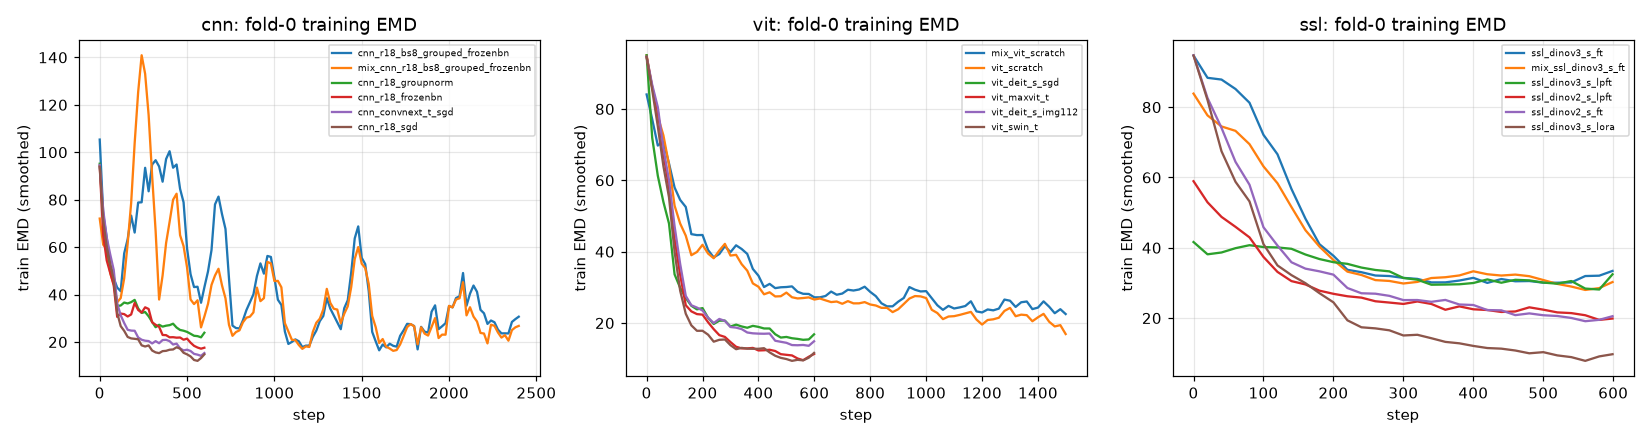

In [11]:
display(show(['vit_scratch', 'vit_deit_s', 'cnn_r18_adamw', 'vit_deit_s_nollrd', 'vit_deit_s_nowarm', 'vit_deit_s_sgd',
              'vit_deit_s_wd_all', 'vit_deit_s_dp0', 'vit_deit_s_img112', 'vit_deit_s_strongaug', 'vit_swin_t', 'vit_maxvit_t']))
display(Image(R / 'figures/training_curves.png'))

## Part 3. Self-supervised encoders

In [12]:
ssl = res[res.family == 'ssl'].copy()
frz = ssl[ssl.name.str.contains('_ridge_|_knn_|_lp_')]
frz = frz.assign(encoder=frz.name.str.extract(r'^(\w+?_s(?:_da)?)_')[0], head=frz.name.str.extract(r'_(ridge|knn|lp)_')[0],
                 feats=frz.name.str.extract(r'_(?:ridge|knn|lp)_(\w+)$')[0])
display(frz.pivot_table(index=['encoder'], columns=['head', 'feats'], values='cv_mean').round(2))
display(show([n for n in res.name if n.startswith('ssl_')]).join(res.set_index('name')['cka']))

head             knn                    lp  ridge                                         
feats       clspatch clspatch_tth clspatch block4 block4_tth block8    cls clspatch  patch
encoder                                                                                   
deit_s         37.97          NaN    41.38  40.59        NaN  40.86  45.20    41.88  41.71
dinov2_s       39.23          NaN    44.28  40.61        NaN  43.04  42.63    42.47  42.43
dinov2_s_da    37.33          NaN    45.79  36.51      36.51  44.31  49.50    48.17  46.94
dinov3_s       36.56        36.56    45.04  42.88        NaN  43.48  41.43    41.76  42.05

,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb,cka
name,,,,,,,
ssl_dinov3_s_ft,34.059,16.043,0.286,79.853,0.048,3.71,0.801544
ssl_dinov3_s_ft_tth,34.059,16.043,0.286,NaN,0.048,3.71,0.801544
ssl_dinov3_s_lpft,37.693,17.814,0.326,NaN,0.056,3.71,0.965728
ssl_dinov2_s_lpft,40.700,20.682,0.375,NaN,0.043,3.84,0.838635
ssl_dinov2_s_ft,44.089,21.964,0.397,NaN,0.038,3.85,0.682906
ssl_dinov3_s_lora,44.895,21.064,0.429,NaN,0.048,3.07,0.693807
ssl_dinov2_s_lora,46.539,21.161,0.441,NaN,0.036,3.13,0.647408
ssl_dinov2_s_da_lpft,47.469,19.303,0.443,NaN,0.044,3.85,0.868460
ssl_dinov2_s_da_lora,48.942,17.979,0.463,NaN,0.035,3.13,0.622099


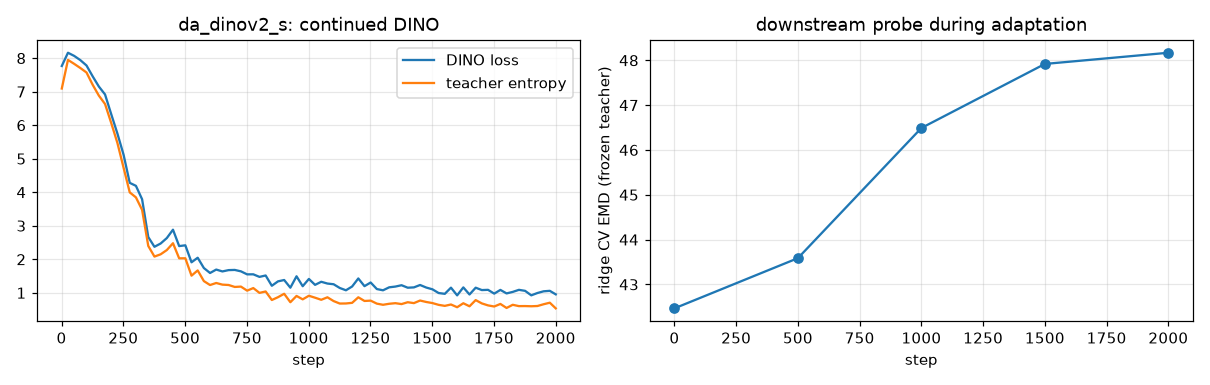

In [13]:
for p in sorted((R / 'figures').glob('da_*_curves.png')):
    display(Image(p))

## Part 4. Interpretation and shortcut controls

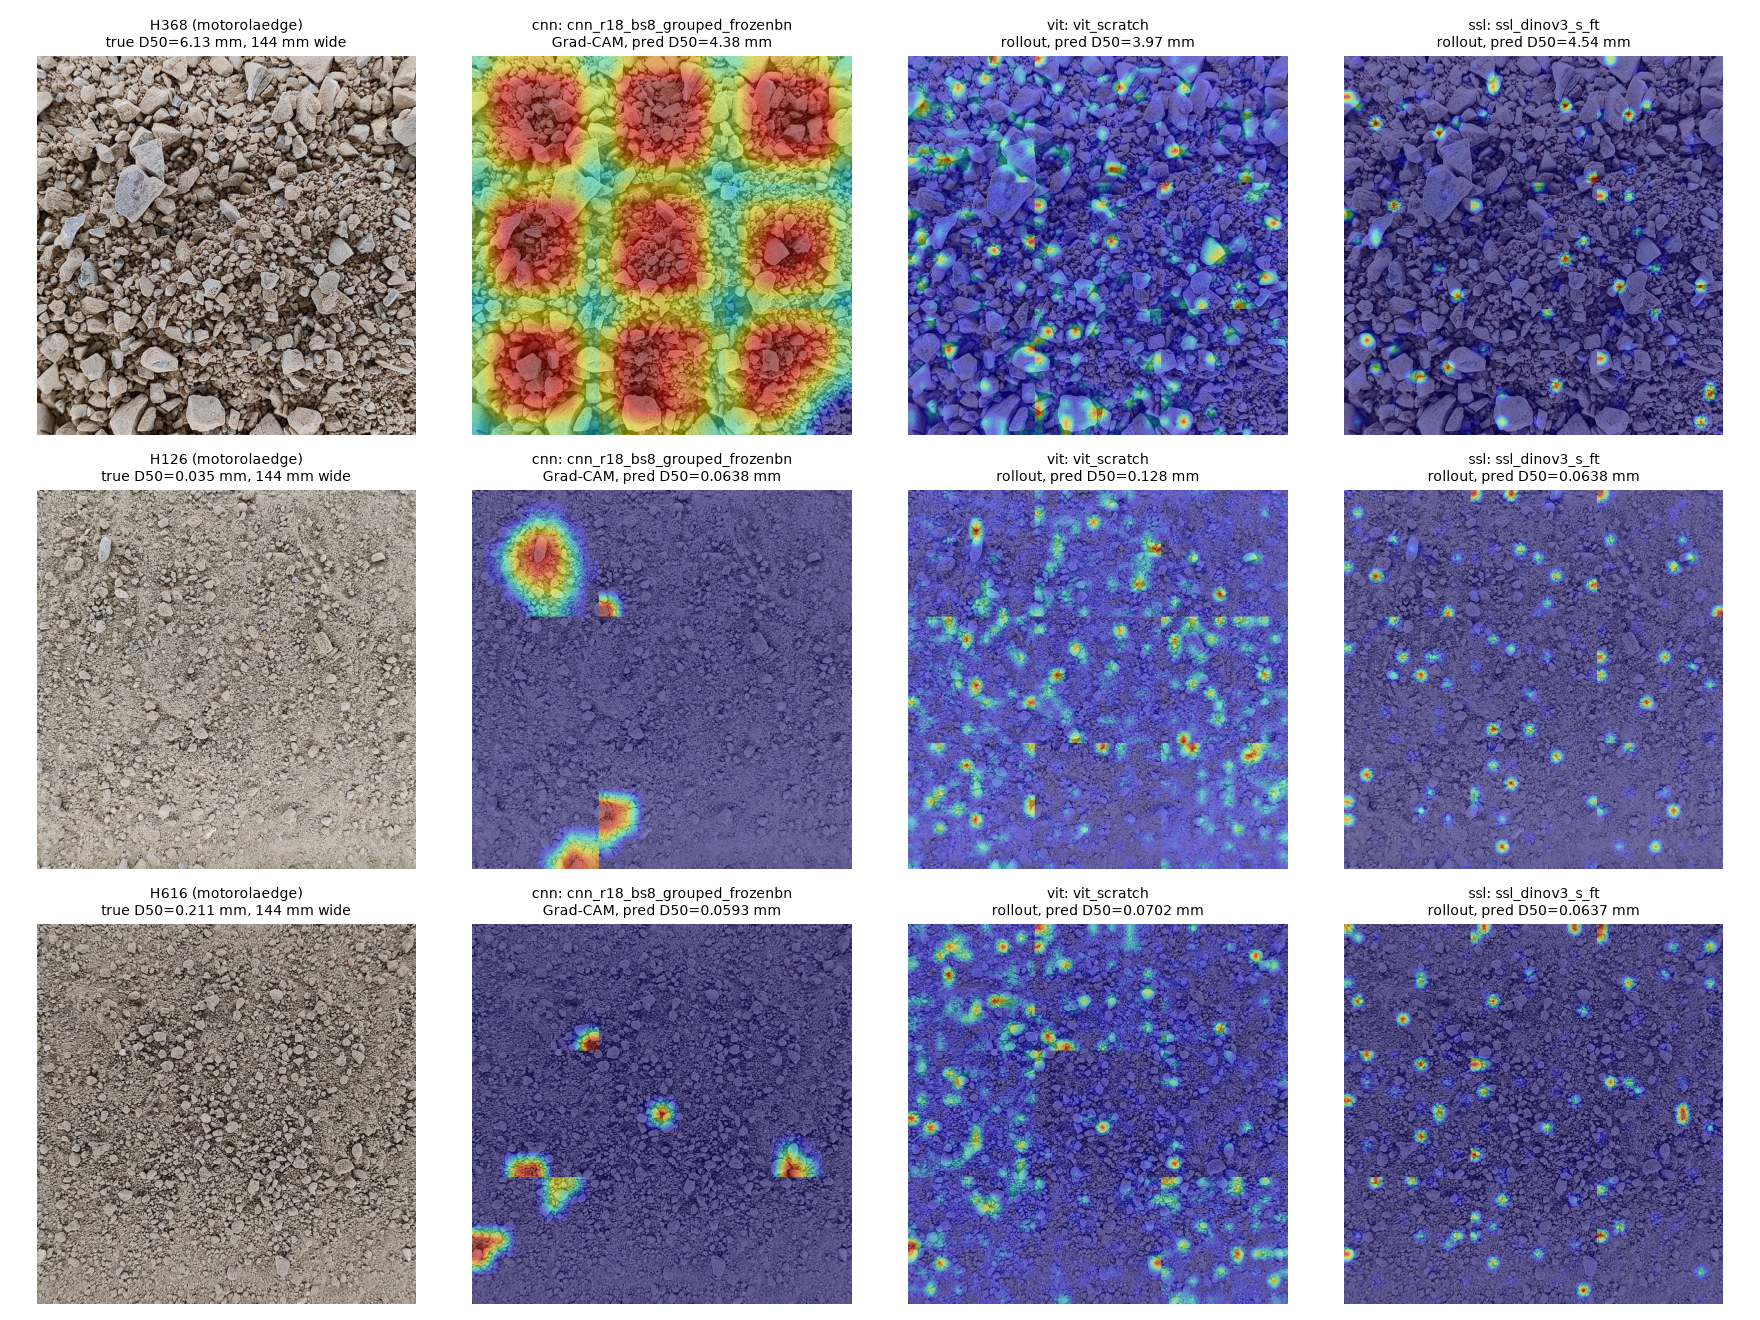

,sample_id,family,model,pred_d50_mm,true_d50_mm,map_centre_vs_border
0,H368,cnn,cnn_r18_bs8_grouped_frozenbn,4.380,6.126,0.922
1,H368,vit,vit_scratch,3.973,6.126,0.978
2,H368,ssl,ssl_dinov3_s_ft,4.545,6.126,0.939
3,H126,cnn,cnn_r18_bs8_grouped_frozenbn,0.064,0.035,0.273
4,H126,vit,vit_scratch,0.128,0.035,1.046
5,H126,ssl,ssl_dinov3_s_ft,0.064,0.035,0.976
6,H616,cnn,cnn_r18_bs8_grouped_frozenbn,0.059,0.211,0.968
7,H616,vit,vit_scratch,0.070,0.211,0.924
8,H616,ssl,ssl_dinov3_s_ft,0.064,0.211,0.958


,name,cv_mean,ctrl_shuffle,ctrl_grey
28,ssl_dinov3_s_ft,34.06,33.77,34.15
29,ssl_dinov3_s_ft_tth,34.06,33.77,34.15
68,mix_vit_scratch,34.53,34.43,46.62
69,vit_scratch,35.28,35.57,48.83
5,cnn_r18_bs8_grouped_frozenbn_tth,35.88,35.66,35.13
4,cnn_r18_bs8_grouped_frozenbn,35.88,35.66,35.13


,cv_mean,cv_std,D50_err_dec,lb_public,gpu_hours,peak_mem_gb
name,,,,,,
base_uniform,102.020,5.477,0.914,NaN,0.0,0.0
base_train_mean,86.632,3.037,0.923,102.372,0.0,0.0
ctrl_camera_only,87.055,2.713,0.929,NaN,0.0,0.0
ctrl_colour_only,49.689,15.760,0.424,NaN,0.0,0.0


In [14]:
display(Image(R / 'figures/interpretation_maps.png'))
display(pd.read_csv(R / 'interpretation.csv').round(3))
ctrl = res[res.ctrl_shuffle.notna()].sort_values('cv_mean').groupby('family').head(2)
display(ctrl[['name', 'cv_mean', 'ctrl_shuffle', 'ctrl_grey']].round(2))
display(show(['base_uniform', 'base_train_mean', 'ctrl_camera_only', 'ctrl_colour_only']))

## Part 6. Comparison of approaches and scale robustness

,family,name,cv_mean,cv_std,lb_public,gpu_hours,peak_mem_gb,params_m,trainable_m,scale_ref,res_0.5,res_0.25,ppm_x0.5,ppm_x2
28,ssl,ssl_dinov3_s_ft,34.059,16.043,79.853,0.048,3.71,21.59,21.591,34.190,34.384,35.869,39.814,37.935
68,vit,mix_vit_scratch,34.529,17.261,NaN,0.048,2.53,2.86,2.857,34.452,35.912,42.408,45.837,40.320
5,cnn,cnn_r18_bs8_grouped_frozenbn_tth,35.878,17.187,NaN,0.053,3.21,11.18,11.173,36.395,36.900,39.736,46.352,42.392


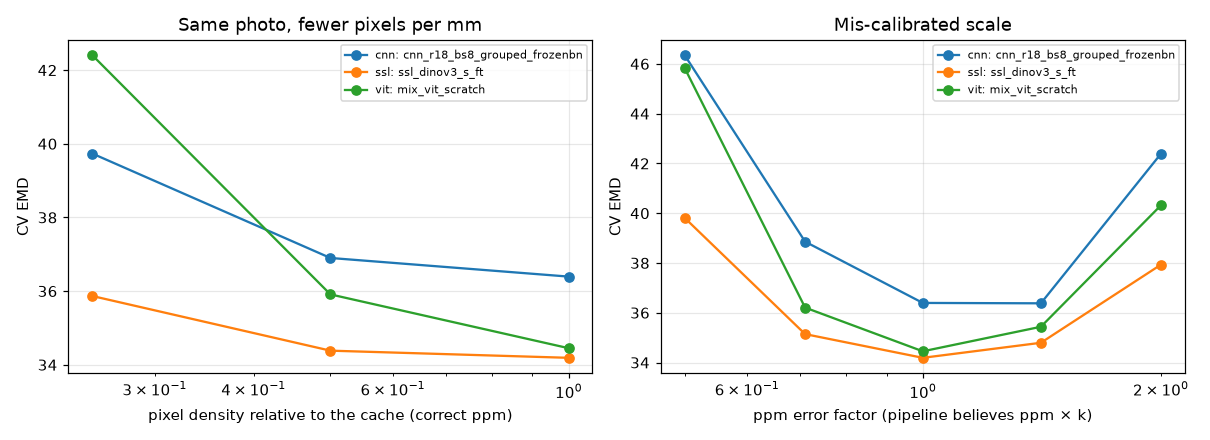

,class,cnn,ssl,vit
0,fine,35.36,31.92,32.68
1,gravel,27.72,26.25,26.95
2,sand,59.47,60.36,59.53


In [15]:
best = res[res.family.isin(['cnn', 'vit', 'ssl'])].sort_values('cv_mean').groupby('family').head(1)
display(best[['family', 'name', 'cv_mean', 'cv_std', 'lb_public', 'gpu_hours', 'peak_mem_gb', 'params_m', 'trainable_m',
              'scale_ref', 'res_0.5', 'res_0.25', 'ppm_x0.5', 'ppm_x2']].round(3))
display(Image(R / 'figures/scale_robustness.png'))
display(pd.read_csv(R / 'error_by_class.csv'))

## Part 7. Ensemble

In [16]:
display(pd.read_csv(R / 'oof_error_corr.csv', index_col=0).round(2))
display(pd.read_csv(R / 'ensembles.csv'))
print(json.dumps(json.loads((R / 'final_choice.json').read_text()), indent=1))

,ssl_dinov3_s_ft,vit_scratch,cnn_r18_bs8_grouped_frozenbn,dinov2_s_da_ridge_block4,dinov3_s_knn_clspatch,dinov2_s_da_knn_clspatch,cnn_r18_groupnorm,ssl_dinov3_s_lpft,deit_s_knn_clspatch,dinov2_s_knn_clspatch,cnn_r18_frozenbn,cnn_convnext_t_sgd
ssl_dinov3_s_ft,1.00,0.89,0.98,0.77,0.78,0.77,0.92,0.95,0.81,0.84,0.88,0.84
vit_scratch,0.89,1.00,0.92,0.85,0.72,0.75,0.94,0.86,0.85,0.80,0.96,0.94
cnn_r18_bs8_grouped_frozenbn,0.98,0.92,1.00,0.83,0.80,0.80,0.96,0.96,0.85,0.85,0.92,0.89
dinov2_s_da_ridge_block4,0.77,0.85,0.83,1.00,0.82,0.87,0.88,0.82,0.87,0.86,0.91,0.89
dinov3_s_knn_clspatch,0.78,0.72,0.80,0.82,1.00,0.96,0.82,0.85,0.94,0.94,0.81,0.81
dinov2_s_da_knn_clspatch,0.77,0.75,0.80,0.87,0.96,1.00,0.85,0.85,0.92,0.95,0.85,0.83
cnn_r18_groupnorm,0.92,0.94,0.96,0.88,0.82,0.85,1.00,0.91,0.90,0.85,0.97,0.93
ssl_dinov3_s_lpft,0.95,0.86,0.96,0.82,0.85,0.85,0.91,1.00,0.86,0.89,0.88,0.87
deit_s_knn_clspatch,0.81,0.85,0.85,0.87,0.94,0.92,0.90,0.86,1.00,0.93,0.90,0.93
dinov2_s_knn_clspatch,0.84,0.80,0.85,0.86,0.94,0.95,0.85,0.89,0.93,1.00,0.85,0.87


,ensemble,members,cv_mean,cv_std,mean_pair_corr
0,best single,['ssl_dinov3_s_ft'],34.058946,16.042973,NaN
1,ens_best_per_family,"['vit_scratch', 'cnn_r18_bs8_grouped_frozenbn'...",33.919898,16.920954,0.930564
2,ens_top3,"['ssl_dinov3_s_ft', 'vit_scratch', 'cnn_r18_bs...",33.919898,16.920954,0.930564
3,ens_top5,"['ssl_dinov3_s_ft', 'vit_scratch', 'cnn_r18_bs...",33.525144,15.809339,0.835780
4,ens_diverse2,"['vit_scratch', 'dinov3_s_knn_clspatch']",33.926560,15.188066,0.715337
5,ens_diverse3,"['ssl_dinov3_s_ft', 'dinov2_s_da_ridge_block4'...",33.675411,14.054817,0.792541


{
 "chosen_by": "CV mean EMD",
 "name": "ens_top5",
 "cv_mean": 33.52514431930482,
 "cv_std": 15.80933868155803,
 "best_single": "ssl_dinov3_s_ft",
 "best_single_cv": 34.05894585138363,
 "family_best": {
  "vit": "vit_scratch",
  "cnn": "cnn_r18_bs8_grouped_frozenbn",
  "ssl": "ssl_dinov3_s_ft"
 },
 "family_error_corr": {
  "vit": {
   "vit": 1.0,
   "cnn": 0.921,
   "ssl": 0.894
  },
  "cnn": {
   "vit": 0.921,
   "cnn": 1.0,
   "ssl": 0.976
  },
  "ssl": {
   "vit": 0.894,
   "cnn": 0.976,
   "ssl": 1.0
  }
 }
}


## Block 8. Test-time harmonisation and soil-mixup

In [17]:
print(json.dumps(json.loads((R / 'harmonisation.json').read_text()), indent=1))
cls = curves.set_index('sample_id')['class']
rows = []
for n in ['cnn_r18_bs8_grouped_frozenbn', 'mix_cnn_r18_bs8_grouped_frozenbn', 'vit_scratch', 'mix_vit_scratch', 'ssl_dinov3_s_ft', 'mix_ssl_dinov3_s_ft']:
    m = json.loads((R / 'exps' / n / 'metrics.json').read_text())
    by = pd.Series(m['per_sample']).groupby(cls).mean().round(1).to_dict()
    rows.append({'name': n, 'cv': round(m['cv_mean'], 2), **by})
display(pd.DataFrame(rows).set_index('name'))

{
 "jpeg_quality": {
  "motorolaedge": 75,
  "samsunga52": 75
 },
 "long_side": 1600,
 "sharpness": {
  "train (messenger)": 0.24892611801624298,
  "test original": 0.23906438052654266,
  "test harmonised": 0.2620537579059601
 },
 "dinov3_nn_cosine_distance": {
  "test original": 0.1243866808358727,
  "test harmonised": 0.10969268928980647
 },
 "H374_check": [
  {
   "model": "ssl_dinov3_s_ft",
   "H374_original": 21.0,
   "H374_harmonised": 22.22
  },
  {
   "model": "vit_scratch",
   "H374_original": 28.62,
   "H374_harmonised": 30.18
  },
  {
   "model": "cnn_r18_bs8_grouped_frozenbn",
   "H374_original": 50.37,
   "H374_harmonised": 51.75
  }
 ],
 "test_shift_emd": {
  "ssl_dinov3_s_ft": 1.6538640047967417,
  "vit_scratch": 0.981207455983992,
  "cnn_r18_bs8_grouped_frozenbn": 1.914179910253407,
  "dinov3_s_knn_clspatch": 6.687468436283892,
  "dinov2_s_da_ridge_block4": 5.817976876897136,
  "ens_top5": 3.13069607594266
 }
}


,cv,fine,gravel,sand
name,,,,
cnn_r18_bs8_grouped_frozenbn,35.88,35.4,27.7,59.5
mix_cnn_r18_bs8_grouped_frozenbn,36.39,36.1,28.6,58.5
vit_scratch,35.28,35.4,26.5,59.2
mix_vit_scratch,34.53,32.7,27.0,59.5
ssl_dinov3_s_ft,34.06,31.9,26.2,60.4
mix_ssl_dinov3_s_ft,34.64,33.9,26.9,57.6


## Appendix 2. Practical exercises (checked numerically)

In [18]:
# 1. ViT-S/16 on 1024x1024
D, N = 384, (1024 // 16) ** 2 + 1
print('Ex1 tokens', N, '| attn matrix fp16 MB', N * N * 2 / 2**20, '| MACs/block linear', 12 * N * D**2 / 1e9, 'G, attn', 2 * N**2 * D / 1e9, 'G')
tot_big = 12 * (12 * N * D**2 + 2 * N**2 * D); n2 = 14 * 14 + 1; tot_tiles = 16 * 12 * (12 * n2 * D**2 + 2 * n2**2 * D)
print('     total 1024^2:', tot_big / 1e9, 'G MACs vs 16 tiles of 224:', tot_tiles / 1e9, 'G')
# 2. Swin stage 1
h = w = 56; C = 96; M = 7
msa, wmsa = 4*h*w*C**2 + 2*(h*w)**2*C, 4*h*w*C**2 + 2*M**2*h*w*C
print('Ex2 MSA', msa / 1e9, 'G  W-MSA', wmsa / 1e9, 'G  ratio', msa / wmsa)
# 3. weighted k-NN
s = np.array([0.9, 0.8, 0.75, 0.6]); cls = np.array(list('ABBB'))
for tau in (0.1, 1):
    wts = np.exp(s / tau); print('Ex3 tau', tau, {c: round(wts[cls == c].sum() / wts.sum(), 3) for c in 'AB'})
wts = np.exp(s / 0.1); print('    regression', (wts * np.array([60, 40, 50, 30])).sum() / wts.sum())
# 4. RankMe
sig = np.array([4, 2, 1, 1.]); p = sig / sig.sum(); print('Ex4 RankMe', np.exp(-(p * np.log(p)).sum()), '(min 1, max 4)')
# 5. linear CKA
cka = lambda X, Y: np.linalg.norm(Y.T @ X)**2 / (np.linalg.norm(X.T @ X) * np.linalg.norm(Y.T @ Y))
X = np.array([[1, 2, 3, 4.]]).T; X -= X.mean()
for Yv in ([2, 4, 6, 8.], [1, -1, 1, -1.]):
    Yc = np.array([Yv]).T; Yc -= Yc.mean(); print('Ex5 CKA', round(cka(X, Yc), 4))
# 6. valid curve
print('Ex6', make_valid(np.array([10, 35, 30, 80, 105.]), 'max')[0], make_valid(np.array([10, 35, 30, 80, 105.]), 'isotonic')[0])
# 7. EMD on a log grid
d = np.array([0.1, 1, 10]); P = np.array([20, 50, 100.]); T = np.array([40, 60, 100.])
lg = np.log10(d); print('Ex7 EMD', (np.abs(P - T)[:-1] * np.diff(lg)).sum(),
      'D50 pred', 10**np.interp(50, P, lg), 'D50 true', 10**np.interp(50, T, lg), 'x2 scale error EMD', 100 * np.log10(2))
# 8. DINO centering / sharpening
t = np.array([2, 0, 0.]); c = np.array([1, 0, -1.]); sm = lambda z: np.exp(z - z.max()) / np.exp(z - z.max()).sum()
print('Ex8', sm((t - c) / 0.5).round(4), sm(t / 0.5).round(4), 'new centre', 0.9 * c + 0.1 * t)
# 9. LoRA
r = 8; lora = 12 * (r * (384 + 1152) + r * (384 + 384)); print('Ex9 LoRA params', lora, 'share', lora / 22e6, 'full qkv', 384 * 1152)
# 10. Grad-CAM by hand
A1, A2 = np.array([[1, 0], [2, 1.]]), np.array([[0, 3], [1, 0.]]); a1, a2 = 0.5, -0.25
print('Ex10 alphas', a1, a2, 'map', np.maximum(a1 * A1 + a2 * A2, 0))

Ex1 tokens 4097 | attn matrix fp16 MB 32.01562690734863 | MACs/block linear 7.249526784 G, attn 12.891194112 G
     total 1024^2: 241.688650752 G MACs vs 16 tiles of 224: 72.651128832 G
Ex2 MSA 2.003828736 G  W-MSA 0.145108992 G  ratio 13.809128630705395
Ex3 tau 0.1 {'A': np.float64(0.609), 'B': np.float64(0.391)}
Ex3 tau 1 {'A': np.float64(0.285), 'B': np.float64(0.715)}
    regression 53.24565762431844
Ex4 RankMe 3.363585661014858 (min 1, max 4)
Ex5 CKA 1.0
Ex5 CKA 0.2
Ex6 [ 10.  35.  35.  80. 100.] [ 10.   32.5  32.5  80.  100. ]
Ex7 EMD 30.0 D50 pred 1.0 D50 true 0.31622776601683794 x2 scale error EMD 30.10299956639812
Ex8 [0.4683 0.0634 0.4683] [0.9647 0.0177 0.0177] new centre [ 1.1  0.  -0.9]
Ex9 LoRA params 221184 share 0.010053818181818181 full qkv 442368
Ex10 alphas 0.5 -0.25 map [[0.5  0.  ]
 [0.75 0.5 ]]
